# 01 · Définir le problème et explorer les données

**Étapes 1–2** du cas pratique · Slides 5, 10, 17–21, 23, 40, 44.

Ce notebook cadre le problème (étape 1) puis explore les données (étape 2). Chaque question numérotée est suivie, juste après le code qui permet d'y répondre, d'une cellule de réponse.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

from financial_inclusion_africa import config
from financial_inclusion_africa.data import load_raw
from financial_inclusion_africa.evaluate import (
    classification_metrics,
    full_classification_report,
    theoretical_threshold,
)

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)

## Étape 1 · Définir le problème

### 1.1 Le contexte

Jeu de données **Financial Inclusion in Africa** (Zindi), issu des enquêtes ménages FinScope 2016–2018 au Kenya, au Rwanda, en Tanzanie et en Ouganda. Chaque ligne est une personne interrogée ; la cible `bank_account` indique si elle possède un compte bancaire.

### 1.2 Le scénario métier

- **KaziPay** contacte (SMS puis agent) les personnes dont elle pense qu'elles ont un compte bancaire.
  - Contacter une personne **sans compte** coûte $C_{FP} = 0{,}5$ USD (faux positif).
  - **Ne pas** contacter une personne qui a un compte bancaire fait perdre $C_{FN} = 5$ USD (faux négatif).
- La **banque centrale** estime le nombre de personnes qui ont un compte bancaire par pays en additionnant les probabilités prédites.

$$\text{Coût} = C_{FP}\cdot FP + C_{FN}\cdot FN \qquad\qquad t^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Les coûts sont fixés une fois pour toutes dans `config.py`.

In [2]:
df = load_raw()
print(f"{df.shape[0]:,} lignes × {df.shape[1]} colonnes")
df.head()

23,524 lignes × 13 colonnes


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,1,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,0,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,1,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,0,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,0,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


### Q1.1 · Unité statistique, cible, classe positive, type de problème

In [3]:
counts = df[config.TARGET].value_counts().rename({0: "No (0)", 1: "Yes (1)"})
prevalence = df[config.TARGET].mean()
display(counts.to_frame("effectif").assign(part=lambda t: t["effectif"] / len(df)))
print(f"Prévalence de la classe positive : {prevalence:.2%}")

,effectif,part
bank_account,,
No (0),20212,0.8592
Yes (1),3312,0.1408


Prévalence de la classe positive : 14.08%


**Réponse Q1.1.**

- **Unité statistique** : une **personne interrogée** (un adulte d'un ménage enquêté par FinScope), dans un pays et une année donnés. Ce n'est ni le ménage ni le pays.
- **Variable cible** : `bank_account`, encodée 1 = *Yes*, 0 = *No* par `load_raw()`.
- **Classe positive** : **1 = la personne possède un compte bancaire**. C'est la classe que KaziPay veut trouver ; elle est **minoritaire** (14,08 %, soit 3 312 personnes sur 23 524).
- **Type de problème** : **classification binaire supervisée, déséquilibrée** (environ 1 positif pour 6 négatifs). On attend du modèle des **probabilités** et pas seulement une étiquette, parce que les deux usages métier en ont besoin : un seuil fondé sur les coûts pour KaziPay et une somme de probabilités pour la banque centrale.

### Q1.2 · Le modèle qui répond « Non » pour tout le monde

In [4]:
X, y = df.drop(columns=config.TARGET), df[config.TARGET]
t_star = theoretical_threshold(config.COST_FP, config.COST_FN)

# Deux planchers : « toujours Non » (proba 0 pour tous) et « prior » (proba = prévalence pour tous)
planchers = {
    "« toujours Non »": DummyClassifier(strategy="most_frequent"),
    "« prior » (p = 14 %)": DummyClassifier(strategy="prior"),
}
proba = {name: m.fit(X, y).predict_proba(X)[:, 1] for name, m in planchers.items()}
pd.DataFrame({name: classification_metrics(y, p, t_star) for name, p in proba.items()})

,« toujours Non »,« prior » (p = 14 %)
pr_auc,0.1408,0.1408
roc_auc,0.5000,0.5000
brier,0.1408,0.1210
log_loss,5.0747,0.4064
accuracy,0.8592,0.1408
precision,0.0000,0.1408
recall,0.0000,1.0000
f1,0.0000,0.2468
cost,16560.0000,10106.0000


In [5]:
print("Rapport de classification · « toujours Non »\n")
print(full_classification_report(y, proba["« toujours Non »"], t_star))

Rapport de classification · « toujours Non »



              precision    recall  f1-score   support

      No (0)     0.8592    1.0000    0.9243     20212
     Yes (1)     0.0000    0.0000    0.0000      3312

    accuracy                         0.8592     23524
   macro avg     0.4296    0.5000    0.4621     23524
weighted avg     0.7382    0.8592    0.7941     23524



**Réponse Q1.2.** Le modèle « toujours Non » obtient une **accuracy de 85,92 %** ($= 1 - 14{,}08\,\%$, exactement la part de la classe majoritaire) et un **recall de 0** : il ne trouve **aucune** personne qui a un compte bancaire, KaziPay ne contacte personne et perd $3\,312 \times 5 = 16\,560$ USD de marge.

Le **rapport de classification** le montre classe par classe : tout semble excellent pour *No* (recall 1, F1 0,92) et tout vaut **0 pour *Yes***, la seule classe qui intéresse KaziPay. La moyenne pondérée (F1 0,79) est dominée par la classe majoritaire et masque cet échec ; la moyenne macro (recall 0,50) le révèle.

Les métriques de **probabilités** le sanctionnent aussi : en donnant une probabilité **0** à 3 312 personnes qui ont un compte, il obtient une **log-loss de 5,07**, contre **0,41** pour le plancher « prior », qui donne 14 % à tout le monde. La log-loss punit très fort les erreurs commises avec certitude. Le plancher « prior » est la référence à battre pour la log-loss (0,406) et le Brier (0,121) ; au seuil $t^*$ elle contacte tout le monde (recall 1, précision 0,14).

**Conclusion (slide 21)** : avec des classes déséquilibrées, l'accuracy est trompeuse. Un score de 86 % semble bon alors que le modèle est inutile. L'accuracy ne dit rien de la classe qui nous intéresse ; elle reste au mieux une métrique de contrôle, toujours comparée à ces **planchers** (`DummyClassifier`). Le vrai modèle de base, à battre par tous les modèles plus complexes, est la **régression logistique** (voir « Choix du modèle de base » ci-dessous).

### Q1.3 · Métrique principale et métriques secondaires

**Réponse Q1.3.**

| Rôle | Métrique | Pourquoi |
|---|---|---|
| **Principale** | **PR-AUC** (*average precision*) | Classe positive rare (14 %) : elle ne regarde que la qualité du classement **parmi les positifs**, sans être gonflée par les 86 % de vrais négatifs faciles (slides 18–19). Indépendante du seuil, donc utile pour comparer et régler les modèles avant de choisir $t^*$. Référence du hasard = prévalence ≈ 0,14. |
| Secondaire 1 | **Score de Brier** (+ ECE, diagramme de fiabilité) | Usage **banque centrale** : on additionne des probabilités, elles doivent être **calibrées** (slide 40). Le Brier mesure l'exactitude des probabilités elles-mêmes. |
| Secondaire 2 | **Coût total** $C_{FP}\cdot FP + C_{FN}\cdot FN$ au seuil retenu | Usage **KaziPay** : c'est la grandeur que l'entreprise veut minimiser, en dollars, lisible par le métier (slide 17). |

**Métriques rapportées en complément**, toujours en **moyenne ± écart-type** sur les plis de validation croisée :

- **ROC-AUC** : qualité du classement, à comparer avec la littérature ;
- **log-loss** : avec le Brier, juge les probabilités ; elle punit fortement les erreurs commises avec certitude ;
- au seuil retenu : **précision** (part des personnes contactées qui ont un compte), **recall** (part des personnes qui ont un compte que l'on contacte), **accuracy** ;
- le **rapport de classification complet** (`classification_report` : précision, recall, F1 et support par classe, moyennes macro et pondérée).

Ces métriques sont calculées par `classification_metrics()` et `full_classification_report()` dans `evaluate.py`, pour être identiques dans tous les notebooks.

### Choix du modèle de base (baseline)

**Décision : la régression logistique est notre modèle de base.** Tout modèle plus complexe (forêt aléatoire, boosting) devra la battre pour justifier sa complexité.

| Rôle | Modèle | Ce qu'il nous apprend |
|---|---|---|
| Plancher | `DummyClassifier` (« toujours Non », « prior ») | Le score obtenu **sans rien apprendre**. Un modèle qui ne le bat pas largement est cassé (Q1.2). |
| **Modèle de base** | **`LogisticRegression`** | Le score d'un modèle **simple, rapide et interprétable**. C'est la référence pour toutes les comparaisons suivantes. |

**Pourquoi la régression logistique ?** (slide 21 : *« modèle linéaire régularisé, simple et rapide »*)
- **Simple et rapide** : quelques secondes en validation croisée, peu d'hyperparamètres (la régularisation `C`).
- **Interprétable** : chaque coefficient se lit comme un *odds ratio* ; on peut l'expliquer à KaziPay et à la banque centrale.
- **Probabilités souvent bien calibrées** : elle est entraînée en minimisant la log-loss, ce qui sert directement la banque centrale (Q1.5) et le seuil $t^*$ (Q1.4).
- **Peu de variance** : elle surapprend peu, ce qui donne un point de comparaison stable pour le diagnostic biais–variance (étape 5).

**Règle de comparaison** : un modèle plus complexe ne « bat » la régression logistique que si son gain de PR-AUC dépasse l'**écart-type** entre les plis de validation croisée. Sinon, on garde le modèle le plus simple.

*Mise en œuvre à l'étape 5* (`LogisticRegression(max_iter=2000)` dans le pipeline de l'étape 3, évaluée avec le même objet `cv` que l'étape 4). On ne l'entraîne pas ici : le découpage train/test et le protocole d'évaluation ne sont pas encore en place.

### Q1.4 · Seuil théorique $t^*$

In [6]:
t_star_fn2 = theoretical_threshold(config.COST_FP, 2.0)
print(f"t* (C_FP = {config.COST_FP}, C_FN = {config.COST_FN}) = {t_star:.4f}")
print(f"t* (C_FP = {config.COST_FP}, C_FN = 2.0) = {t_star_fn2:.4f}")

t* (C_FP = 0.5, C_FN = 5.0) = 0.0909
t* (C_FP = 0.5, C_FN = 2.0) = 0.2000


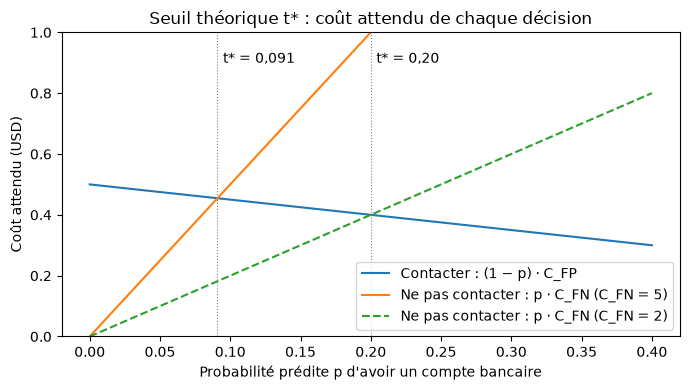

In [7]:
# Coût attendu d'une décision, pour une personne de probabilité p (probabilités calibrées)
p = np.linspace(0, 0.4, 401)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p, (1 - p) * config.COST_FP, label="Contacter : (1 − p) · C_FP")
ax.plot(p, p * config.COST_FN, label="Ne pas contacter : p · C_FN (C_FN = 5)")
ax.plot(p, p * 2.0, ls="--", label="Ne pas contacter : p · C_FN (C_FN = 2)")
for t, lab in [(t_star, "t* = 0,091"), (t_star_fn2, "t* = 0,20")]:
    ax.axvline(t, color="grey", lw=0.8, ls=":")
    ax.annotate(lab, (t, 0.9), xytext=(4, 0), textcoords="offset points")
ax.set(xlabel="Probabilité prédite p d'avoir un compte bancaire", ylabel="Coût attendu (USD)",
       title="Seuil théorique t* : coût attendu de chaque décision", ylim=(0, 1))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_seuil_theorique.png", dpi=150)
plt.show()

**Réponse Q1.4.** On contacte une personne de probabilité $p$ dès que le coût attendu de l'oubli dépasse celui du contact inutile (slide 44) :

$$p\,C_{FN} > (1-p)\,C_{FP} \iff p > t^* = \frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{0{,}5}{0{,}5+5} = \frac{1}{11} \approx 0{,}091.$$

- **Pourquoi bien en dessous de 0,5 ?** Le seuil 0,5 n'est optimal que si les deux erreurs coûtent pareil. Ici rater un client coûte **10 fois** plus cher qu'un SMS inutile : on accepte jusqu'à 10 contacts inutiles pour gagner un client. Il suffit donc d'une chance sur 11 d'avoir un compte bancaire pour que le contact soit rentable.
- **Si $C_{FN}$ descend à 2 USD** : $t^* = 0{,}5/2{,}5 = 0{,}20$. Rater un client coûte moins cher, le seuil **monte**, KaziPay contacte **moins** de personnes (moins de faux positifs, plus de faux négatifs). Le seuil est une décision métier, pas une propriété du modèle.
- **Attention** : cette formule suppose des probabilités **calibrées**. Sinon le seuil empirique qui minimise le coût s'en écartera (étapes 8–9).

### Q1.5 · Ce que la banque centrale exige des probabilités

In [8]:
# Illustration sur des données simulées : deux jeux de scores de même ordre
rng = np.random.default_rng(config.RANDOM_STATE)
p_true = rng.beta(1, 6, size=10_000)       # vraies probabilités (prévalence ≈ 14 %)
y_sim = rng.binomial(1, p_true)
p_biased = p_true / 2                       # même classement, valeurs divisées par 2

pd.DataFrame(
    {
        "ROC-AUC": [roc_auc_score(y_sim, p_true), roc_auc_score(y_sim, p_biased)],
        "Σ p̂ (estimation)": [p_true.sum(), p_biased.sum()],
        "nombre réel de positifs": [y_sim.sum()] * 2,
    },
    index=["p̂ calibrée", "p̂ / 2 (mal calibrée)"],
).round(3)

,ROC-AUC,Σ p̂ (estimation),nombre réel de positifs
p̂ calibrée,0.779,1401.488,1412
p̂ / 2 (mal calibrée),0.779,700.744,1412


**Réponse Q1.5.** La banque centrale estime le nombre de personnes qui ont un compte bancaire par $\sum_i \hat p_i$. Cette somme n'est juste que si les probabilités sont **calibrées** : $P(Y=1 \mid \hat p = p) = p$ (slide 40). Parmi les personnes à qui le modèle donne 20 %, environ 20 % doivent effectivement avoir un compte bancaire, **dans chaque pays**.

**Pourquoi la ROC-AUC ne suffit pas** : elle ne juge que **l'ordre** des scores. Toute transformation croissante des probabilités la laisse inchangée. Dans la simulation ci-dessus, diviser toutes les probabilités par 2 donne **exactement la même ROC-AUC (0,779)**, mais l'estimation tombe de ≈ 1 400 à ≈ 700 personnes : une erreur de 50 %. *Discrimination ≠ calibration* : on mesurera la calibration à part (Brier, ECE, diagramme de fiabilité) et on la corrigera si nécessaire (étape 8).

### Q1.6 · Utiliser le genre pour décider qui contacter ?

In [9]:
pd.crosstab(
    df["gender_of_respondent"], df[config.TARGET], normalize="index", margins=True
).rename(columns={0: "No", 1: "Yes"})

bank_account,No,Yes
gender_of_respondent,,
Female,0.8932,0.1068
Male,0.8103,0.1897
All,0.8592,0.1408


**Réponse Q1.6 (arguments à reprendre à l'étape 11).** Les femmes ont nettement moins souvent un compte bancaire que les hommes dans ces données (**10,7 %** contre **19,0 %**) : le genre est donc prédictif. Mais *prédictif* ne veut pas dire *légitime*.

**Contre l'usage du genre comme critère de décision**
- **Discrimination directe** : le genre est un attribut protégé. À profil égal (éducation, emploi, téléphone…), une femme recevrait une probabilité plus faible, donc moins d'offres.
- **Boucle de rétroaction** : moins sollicitées, les femmes accèdent moins aux services financiers, ce qui renforce l'écart que le modèle a appris. C'est l'inverse de l'objectif d'inclusion financière.
- **Risque juridique et de réputation** pour KaziPay.

**Nuances**
- **Supprimer la colonne ne supprime pas le biais** : `relationship_with_head` (*Spouse*), `marital_status` ou `job_type` peuvent servir de **variables proxy** du genre.
- **Garder le genre pour l'audit** : il faut le conserver *à côté* du modèle pour mesurer l'équité, par exemple comparer le recall des femmes et des hommes au seuil retenu.
- **Usage banque centrale** : estimer un nombre de personnes qui ont un compte bancaire n'est pas une décision individuelle ; le genre y est moins problématique et peut améliorer l'estimation.

**Position provisoire** : ne pas utiliser le genre pour cibler les individus ; entraîner avec et sans, mesurer l'écart de performance et l'écart de recall entre femmes et hommes à l'étape 11, puis trancher.

## Étape 2 · Explorer les données

*À venir.*